# TFM: SVM con características espectrales y temporales (dataset completo)

Modelo clásico de referencia para comparar con las tres arquitecturas de
deep learning. Reutiliza **exactamente las mismas particiones por sujeto**
y la misma señal ya filtrada y normalizada (`datos_procesados_completo_2canales.npz`),
de modo que la comparación es justa.

**Flujo:**
1. Cargar los datos ya procesados (train / val / test por sujeto).
2. Extraer características por época y por canal (potencia por bandas, estadísticos y parámetros de Hjorth).
3. Estandarizar las características con estadísticos **solo de train**.
4. Elegir el parámetro `C` de una SVM lineal con el conjunto de **validación**.
5. Evaluar en test con las mismas métricas que los demás modelos.

**Antes de ejecutar:** ajusta `TFM_DIR` si hace falta.

In [1]:
import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import welch
from scipy.stats import skew, kurtosis

from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, accuracy_score, f1_score,
)

TFM_DIR = os.path.expanduser("~/Desktop/TFM")
IMAGES_DIR = os.path.join(TFM_DIR, "images")
os.makedirs(IMAGES_DIR, exist_ok=True)

NPZ_PATH = os.path.join(TFM_DIR, "datos_procesados_completo_2canales.npz")
FEATURES_PATH = os.path.join(TFM_DIR, "caracteristicas_svm_completo.npz")

FS = 100  # Hz
SEED = 42
np.random.seed(SEED)
print("Datos de entrada:", NPZ_PATH)

Datos de entrada: C:\Users\alber/Desktop/TFM\datos_procesados_completo_2canales.npz


## 1. Funciones de extracción de características

Por cada época de 30 s y por cada canal se calculan 15 características:

- **Potencia por bandas** (delta 0,5-4 Hz, theta 4-8, alfa 8-13, beta 13-30): potencia absoluta en escala logarítmica y potencia relativa (fracción de la potencia total entre 0,5 y 30 Hz). 4 + 4 = 8.
- **Estadísticos temporales:** media, desviación típica, asimetría (*skewness*) y curtosis. 4.
- **Parámetros de Hjorth:** actividad, movilidad y complejidad. 3.

Total: 15 por canal, **30 características por época** con los dos canales.

No se incluye la banda gamma porque el filtro del preprocesamiento (0,5-30 Hz) la elimina.

In [2]:
BANDS = {"delta": (0.5, 4), "theta": (4, 8), "alfa": (8, 13), "beta": (13, 30)}
CHANNELS = ["Fpz-Cz", "Pz-Oz"]

def feature_names():
    names = []
    for ch in CHANNELS:
        for b in BANDS:
            names.append(f"{ch}_logpot_{b}")
        for b in BANDS:
            names.append(f"{ch}_relpot_{b}")
        names += [f"{ch}_media", f"{ch}_std", f"{ch}_skew", f"{ch}_kurt",
                  f"{ch}_hjorth_act", f"{ch}_hjorth_mov", f"{ch}_hjorth_comp"]
    return names

def extract_features(X):
    """X: (n_epocas, n_muestras, n_canales) -> (n_epocas, 30)"""
    X = X.astype(np.float64)
    f, pxx = welch(X, fs=FS, nperseg=256, axis=1)       # pxx: (n, n_freq, n_canales)
    df = f[1] - f[0]

    total_mask = (f >= 0.5) & (f <= 30)
    total_pow = pxx[:, total_mask, :].sum(axis=1) * df + 1e-12

    feats = []
    for c in range(X.shape[2]):
        x = X[:, :, c]
        # Potencia por bandas
        abs_pow, rel_pow = [], []
        for (lo, hi) in BANDS.values():
            m = (f >= lo) & (f < hi)
            p = pxx[:, m, c].sum(axis=1) * df + 1e-12
            abs_pow.append(np.log10(p))
            rel_pow.append(p / total_pow[:, c])
        # Estadísticos temporales
        media = x.mean(axis=1)
        std = x.std(axis=1)
        sk = skew(x, axis=1)
        ku = kurtosis(x, axis=1)
        # Parámetros de Hjorth
        dx = np.diff(x, axis=1)
        ddx = np.diff(dx, axis=1)
        var_x, var_dx, var_ddx = x.var(axis=1) + 1e-12, dx.var(axis=1) + 1e-12, ddx.var(axis=1) + 1e-12
        mov = np.sqrt(var_dx / var_x)
        comp = np.sqrt(var_ddx / var_dx) / mov
        feats += abs_pow + rel_pow + [media, std, sk, ku, var_x, mov, comp]

    return np.column_stack(feats).astype(np.float32)

def extract_in_chunks(X, chunk=5000):
    out = []
    for i in range(0, len(X), chunk):
        out.append(extract_features(X[i:i + chunk]))
        print(f"  {min(i + chunk, len(X))}/{len(X)} épocas", end="\r")
    print()
    return np.vstack(out)

NAMES = feature_names()
print(len(NAMES), "características por época")

30 características por época


## 2. Cargar los datos y extraer características

La extracción se hace una sola vez y se guarda en disco, para no repetirla
cada vez que abras el notebook. Si ya existe el archivo, se carga directamente.

In [3]:
if os.path.exists(FEATURES_PATH):
    d = np.load(FEATURES_PATH)
    F_train, y_train = d["F_train"], d["y_train"]
    F_val, y_val = d["F_val"], d["y_val"]
    F_test, y_test = d["F_test"], d["y_test"]
    print("Características cargadas desde disco.")
else:
    data = np.load(NPZ_PATH)
    t0 = time.time()

    print("Train:")
    F_train = extract_in_chunks(data["X_train_norm"]); y_train = data["y_train"]
    print("Val:")
    F_val = extract_in_chunks(data["X_val_norm"]); y_val = data["y_val"]
    print("Test:")
    F_test = extract_in_chunks(data["X_test_norm"]); y_test = data["y_test"]

    print(f"Extracción terminada en {(time.time() - t0) / 60:.1f} min")
    np.savez(FEATURES_PATH, F_train=F_train, y_train=y_train,
             F_val=F_val, y_val=y_val, F_test=F_test, y_test=y_test)

print("Train:", F_train.shape, "| Val:", F_val.shape, "| Test:", F_test.shape)
print("NaN en train:", np.isnan(F_train).sum(), "| Inf en train:", np.isinf(F_train).sum())

Train:
  205045/205045 épocas
Val:
  46265/46265 épocas
Test:
  44733/44733 épocas
Extracción terminada en 4.4 min
Train: (205045, 30) | Val: (46265, 30) | Test: (44733, 30)
NaN en train: 0 | Inf en train: 0


## 3. Estandarización (solo con estadísticos de train)

Las características tienen escalas muy distintas (potencias logarítmicas,
fracciones, curtosis...), y la SVM es sensible a eso. El `StandardScaler`
se ajusta **solo con train** y se aplica a val y test, igual que se hizo con
la normalización de la señal.

In [4]:
scaler = StandardScaler().fit(F_train)
S_train = scaler.transform(F_train)
S_val = scaler.transform(F_val)
S_test = scaler.transform(F_test)
print("Escalado correcto. Media train ~", S_train.mean().round(4), "| std ~", S_train.std().round(4))

Escalado correcto. Media train ~ 0.0 | std ~ 1.0


## 4. SVM lineal: elegir `C` con el conjunto de validación

Se prueba una pequeña rejilla de valores de `C` y se elige el que mejor
**F1 macro** da en validación (no se mira test para decidir). Se usa
`class_weight="balanced"`, equivalente al ponderado de clases de los modelos
de deep learning.

In [5]:
resultados_C = []
modelos = {}

for C in [0.01, 0.1, 1, 10]:
    t0 = time.time()
    clf = LinearSVC(C=C, class_weight="balanced", dual=False, max_iter=5000, random_state=SEED)
    clf.fit(S_train, y_train)
    pred_val = clf.predict(S_val)
    f1 = f1_score(y_val, pred_val, average="macro")
    acc = accuracy_score(y_val, pred_val)
    resultados_C.append({"C": C, "acc_val": acc, "f1_macro_val": f1, "seg": time.time() - t0})
    modelos[C] = clf
    print(f"C={C:<5} acc_val={acc:.4f}  f1_macro_val={f1:.4f}  ({time.time() - t0:.1f}s)")

tabla_C = pd.DataFrame(resultados_C)
best_C = tabla_C.loc[tabla_C["f1_macro_val"].idxmax(), "C"]
print("\nMejor C según validación:", best_C)
tabla_C

C=0.01  acc_val=0.9316  f1_macro_val=0.9310  (1.3s)
C=0.1   acc_val=0.9312  f1_macro_val=0.9306  (1.4s)
C=1     acc_val=0.9312  f1_macro_val=0.9306  (1.5s)
C=10    acc_val=0.9312  f1_macro_val=0.9306  (1.5s)

Mejor C según validación: 0.01


,C,acc_val,f1_macro_val,seg
0,0.01,0.931611,0.931007,1.273363
1,0.10,0.931222,0.930606,1.423181
2,1.00,0.931222,0.930605,1.454609
3,10.00,0.931222,0.930605,1.461318


## 5. Evaluación en test

              precision    recall  f1-score   support

     Vigilia      0.961     0.878     0.918     25152
       Sueño      0.859     0.955     0.904     19581

    accuracy                          0.912     44733
   macro avg      0.910     0.916     0.911     44733
weighted avg      0.917     0.912     0.912     44733

ROC-AUC: 0.975


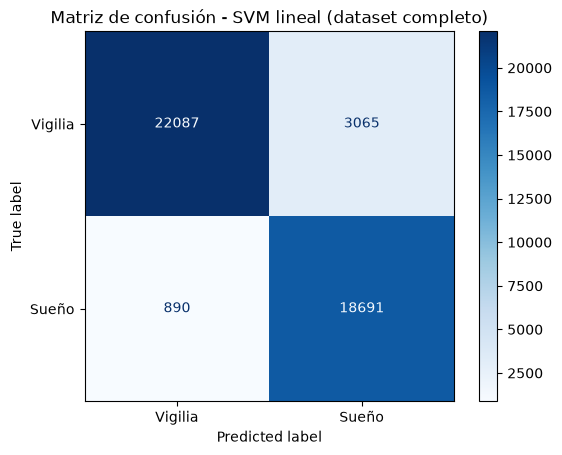

In [6]:
svm = modelos[best_C]

t0 = time.time()
scores_test = svm.decision_function(S_test)
y_pred = (scores_test >= 0).astype(int)
t_inferencia = time.time() - t0

print(classification_report(y_test, y_pred, target_names=["Vigilia", "Sueño"], digits=3))
roc_auc = roc_auc_score(y_test, scores_test)
print(f"ROC-AUC: {roc_auc:.3f}")

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Vigilia", "Sueño"])
disp.plot(cmap="Blues")
plt.title("Matriz de confusión - SVM lineal (dataset completo)")
plt.savefig(os.path.join(IMAGES_DIR, "matriz_confusion_svm.png"), dpi=150, bbox_inches="tight")
plt.show()

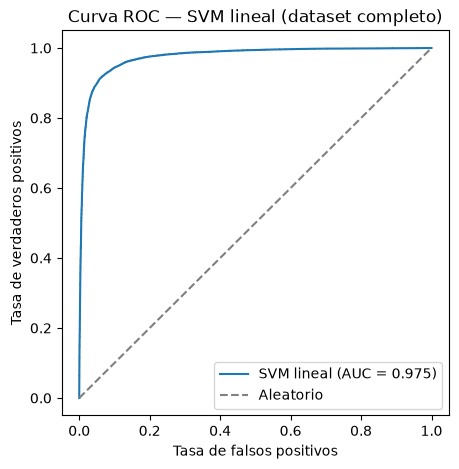

In [7]:
fpr, tpr, _ = roc_curve(y_test, scores_test)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"SVM lineal (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aleatorio")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC — SVM lineal (dataset completo)")
plt.legend()
plt.savefig(os.path.join(IMAGES_DIR, "roc_curve_svm.png"), dpi=150, bbox_inches="tight")
plt.show()

## 6. Qué características pesan más

Una ventaja de la SVM lineal es que cada característica tiene un coeficiente.
Sirve para comentar en el TFM qué información usa el modelo (por ejemplo, si
domina la potencia alfa o la delta).

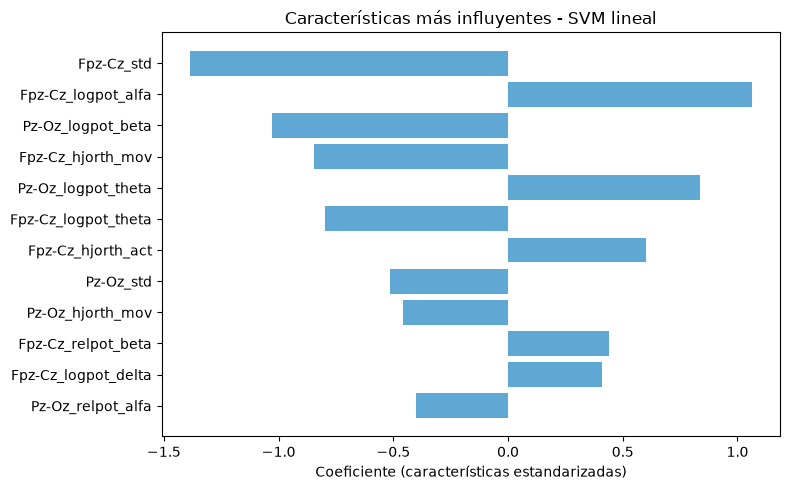

,caracteristica,coeficiente
0,Fpz-Cz_std,-1.386774
1,Fpz-Cz_logpot_alfa,1.062817
2,Pz-Oz_logpot_beta,-1.028881
3,Fpz-Cz_hjorth_mov,-0.843936
4,Pz-Oz_logpot_theta,0.838294
5,Fpz-Cz_logpot_theta,-0.797118
6,Fpz-Cz_hjorth_act,0.602492
7,Pz-Oz_std,-0.514668
8,Pz-Oz_hjorth_mov,-0.456189
9,Fpz-Cz_relpot_beta,0.441185


In [8]:
coef = svm.coef_.ravel()
orden = np.argsort(np.abs(coef))[::-1][:12]

plt.figure(figsize=(8, 5))
plt.barh([NAMES[i] for i in orden][::-1], coef[orden][::-1], color="#5fa8d3")
plt.xlabel("Coeficiente (características estandarizadas)")
plt.title("Características más influyentes - SVM lineal")
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, "caracteristicas_svm.png"), dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({"caracteristica": [NAMES[i] for i in orden], "coeficiente": coef[orden]})

## 8. (Opcional) SVM con núcleo RBF sobre un subconjunto

Solo si quieres probarla. Con 205.045 épocas de entrenamiento la RBF puede
tardar muchas horas, así que se entrena con un **subconjunto aleatorio** de
`N_SUB` épocas. Si la usas en el TFM, debes decir que se entrenó con un
subconjunto, porque no es comparable en igualdad de condiciones con la lineal.

Cambia `RUN_RBF` a `True` para ejecutarla.

In [ ]:
RUN_RBF = False
N_SUB = 30000

if RUN_RBF:
    rng = np.random.RandomState(SEED)
    idx = rng.choice(len(S_train), size=N_SUB, replace=False)

    t0 = time.time()
    rbf = SVC(kernel="rbf", C=1, gamma="scale", class_weight="balanced", random_state=SEED)
    rbf.fit(S_train[idx], y_train[idx])
    print(f"Ajuste RBF con {N_SUB} épocas: {(time.time() - t0) / 60:.1f} min")

    scores_rbf = rbf.decision_function(S_test)
    pred_rbf = (scores_rbf >= 0).astype(int)
    print(classification_report(y_test, pred_rbf, target_names=["Vigilia", "Sueño"], digits=3))
    print(f"ROC-AUC: {roc_auc_score(y_test, scores_rbf):.3f}")
else:
    print("RBF desactivada (RUN_RBF = False).")

## Anota para el TFM

- Particiones: las mismas 54 / 12 / 12 sujetos que los modelos de deep learning.
- Características: 30 por época (15 por canal), calculadas sobre la señal ya filtrada (0,5-30 Hz) y normalizada.
- Escalado y elección de `C`: solo con train y validación.
- Semilla: 42.
- Versiones: ejecuta `import sklearn, scipy, numpy; print(sklearn.__version__, scipy.__version__, numpy.__version__)` y anótalas para el anexo de reproducibilidad.